# 03 · Feature Maps and Kernels

**The cleanest QML idea, and the first honest arena.** A *feature map* encodes classical data into a quantum state. A *quantum kernel* is the fidelity between two encoded states, $K(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2$. It is a genuine PSD kernel, so it drops straight into a scikit-learn SVM — the kernel trick from `kernels_101`, unchanged.

Then we measure. On ordinary data an RBF SVM matches or beats the quantum kernel. The one set where the quantum kernel wins was **engineered to fit its feature map** — shown, and flagged as a caveat, not a triumph.

In [ ]:
import sys, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Resolve the repo root whether this runs from the repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

FIG = ROOT / "outputs" / "figures"
DATA = ROOT / "outputs" / "data"
FIG.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)


def _ser(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, complex):
        return {"re": float(o.real), "im": float(o.imag)}
    raise TypeError(f"not JSON-serializable: {type(o)!r}")


def save_json(name, obj):
    """Save textual/numerical results to outputs/data/<name>."""
    path = DATA / name
    path.write_text(json.dumps(obj, indent=2, default=_ser))
    print("saved", path.relative_to(ROOT))


def save_fig(fig, name):
    """Save a figure as PNG to outputs/figures/<name>."""
    path = FIG / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))


def amp_list(state):
    """A statevector as a JSON-friendly list of {re, im} amplitudes."""
    return [{"re": float(a.real), "im": float(a.imag)} for a in np.asarray(state)]


plt.rcParams.update({"figure.figsize": (7.0, 4.0), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)
print("repo root:", ROOT)


repo root: /workspaces/quantum_ml_101


## A feature map turns a data point into a state

Angle encoding puts $R_Y(x_i)$ on each qubit. The ZZ map adds entangling interactions between features, so the state depends on feature *products* — the structure a linear kernel can't see.

In [2]:
from src.qml.feature_maps import angle_encoding, zz_feature_map
from src.qml.kernels import encoded_state, kernel_matrix, QuantumKernelClassifier

x = np.array([0.6, 1.9])
print('angle-encoded state:', np.round(encoded_state(x, angle_encoding, 2), 3))
print('zz-encoded state:   ', np.round(encoded_state(x, zz_feature_map, 2), 3))

angle-encoded state: [0.556+0.j 0.777+0.j 0.172+0.j 0.24 +0.j]
zz-encoded state:    [ 0.405+0.294j -0.127-0.484j -0.14 +0.48j   0.396-0.305j]


## The quantum kernel matrix

Compute $K$ on a small two-class sample (rows sorted by label). A good kernel shows block structure — points in the same class are more similar. Note the unit diagonal ($|\langle\phi|\phi\rangle|^2 = 1$) and symmetry.

symmetric: True | unit diagonal: True
min eigenvalue (PSD if >= 0): -2.319085243946708e-15


saved outputs/figures/03_kernel_matrix.png
saved outputs/data/03_kernel_matrix.json


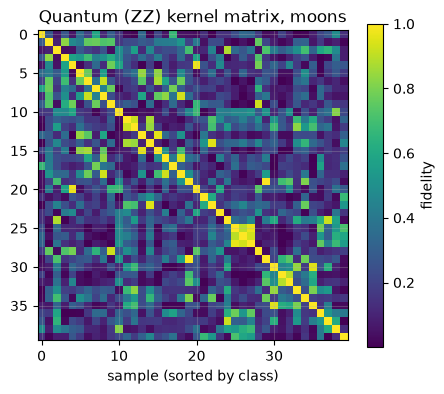

In [3]:
from src.datasets.toy import moons

Xk, yk = moons(n_samples=40, seed=0)
order = np.argsort(yk)
Xk, yk = Xk[order], yk[order]
K = kernel_matrix(Xk, Xk, zz_feature_map, n_qubits=2)
print('symmetric:', bool(np.allclose(K, K.T)), '| unit diagonal:', bool(np.allclose(np.diag(K), 1)))
print('min eigenvalue (PSD if >= 0):', float(np.linalg.eigvalsh(K).min()))

fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(K, cmap='viridis')
ax.set_title('Quantum (ZZ) kernel matrix, moons')
ax.set_xlabel('sample (sorted by class)')
fig.colorbar(im, ax=ax, label='fidelity')
save_fig(fig, '03_kernel_matrix.png')

save_json('03_kernel_matrix.json', {
    'symmetric': bool(np.allclose(K, K.T)),
    'unit_diagonal': bool(np.allclose(np.diag(K), 1)),
    'min_eigenvalue': float(np.linalg.eigvalsh(K).min()),
})

## The arena: quantum kernels vs classical, across datasets

For each dataset we fit logistic regression, an RBF-kernel SVM, and the quantum kernel (angle and ZZ) with a precomputed-kernel SVM, and record held-out accuracy. Same split, same metric — a fair fight.

In [4]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from src.classical.baselines import logistic, rbf_svm
from src.datasets.toy import circles, iris_2d, planted_quantum

datasets = {
    'moons': moons(n_samples=80, seed=0),
    'circles': circles(n_samples=80, seed=0),
    'iris': iris_2d(),
    'planted': planted_quantum(n_samples=120, seed=0),
}

def make_models():
    return {
        'logistic': logistic(),
        'rbf_svm': rbf_svm(),
        'q_kernel_angle': QuantumKernelClassifier(feature_map=angle_encoding, n_qubits=2),
        'q_kernel_zz': QuantumKernelClassifier(feature_map=zz_feature_map, n_qubits=2),
    }

results = {}
for name, (X, y) in datasets.items():
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
    results[name] = {}
    for mname, model in make_models().items():
        model.fit(Xtr, ytr)
        acc = float(accuracy_score(yte, model.predict(Xte)))
        results[name][mname] = acc
    print(name, {k: round(v, 3) for k, v in results[name].items()})

save_json('03_arena.json', results)

moons {'logistic': 0.792, 'rbf_svm': 1.0, 'q_kernel_angle': 0.792, 'q_kernel_zz': 0.75}
circles {'logistic': 0.417, 'rbf_svm': 1.0, 'q_kernel_angle': 1.0, 'q_kernel_zz': 0.75}
iris {'logistic': 1.0, 'rbf_svm': 1.0, 'q_kernel_angle': 1.0, 'q_kernel_zz': 0.933}


planted {'logistic': 0.611, 'rbf_svm': 0.806, 'q_kernel_angle': 0.778, 'q_kernel_zz': 0.944}
saved outputs/data/03_arena.json


saved outputs/figures/03_arena_accuracy.png


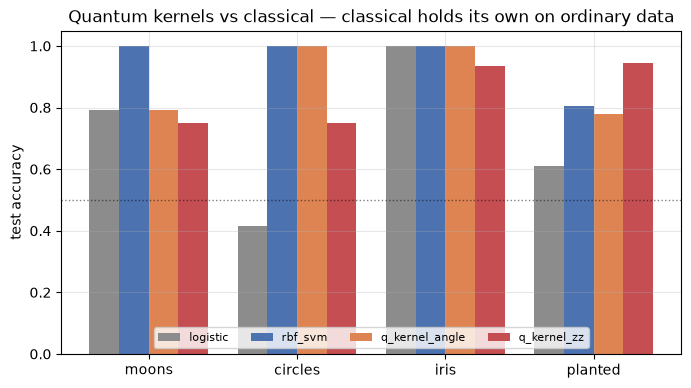

In [5]:
models = ['logistic', 'rbf_svm', 'q_kernel_angle', 'q_kernel_zz']
colors = ['#8c8c8c', '#4c72b0', '#dd8452', '#c44e52']
names = list(datasets)
x = np.arange(len(names))
w = 0.2

fig, ax = plt.subplots(figsize=(8, 4.2))
for i, (m, c) in enumerate(zip(models, colors)):
    ax.bar(x + (i - 1.5) * w, [results[d][m] for d in names], w, label=m, color=c)
ax.set_xticks(x, names)
ax.set_ylabel('test accuracy')
ax.set_ylim(0, 1.05)
ax.axhline(0.5, color='k', ls=':', lw=1, alpha=0.5)
ax.set_title('Quantum kernels vs classical — classical holds its own on ordinary data')
ax.legend(ncol=4, fontsize=8, loc='lower center')
save_fig(fig, '03_arena_accuracy.png')

## The engineered exception, flagged honestly

The `planted` set is the Havlicek *ad hoc* construction: each point is ZZ-encoded into a state, and its label is the sign of $\langle\phi(x)|M|\phi(x)\rangle$ for a fixed random observable $M$. That rule is **linear in the fidelity-kernel feature space**, so the quantum-kernel SVM with the same map can separate it by design, while RBF/logistic on the raw 2-D angles cannot. On it the quantum kernel wins. This is **not** evidence of quantum advantage on real problems; it is a dataset reverse-engineered from the feature map, and we say so.

planted set — quantum ZZ kernel: 0.944  |  best classical: 0.806
quantum wins here


saved outputs/figures/03_planted_spotlight.png
saved outputs/data/03_planted_spotlight.json


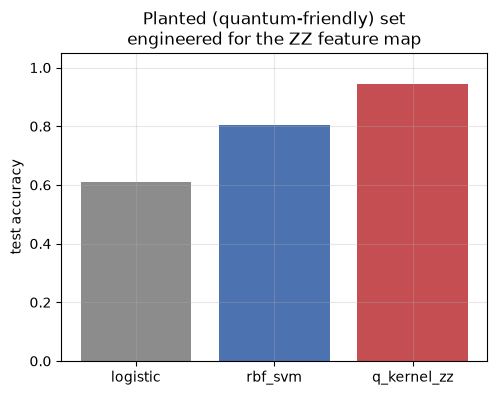

In [6]:
planted = results['planted']
q = planted['q_kernel_zz']
best_classical = max(planted['logistic'], planted['rbf_svm'])
print(f'planted set — quantum ZZ kernel: {q:.3f}  |  best classical: {best_classical:.3f}')
print('quantum wins here' if q > best_classical else 'classical holds')

fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ['logistic', 'rbf_svm', 'q_kernel_zz']
ax.bar(bars, [planted[b] for b in bars], color=['#8c8c8c', '#4c72b0', '#c44e52'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('test accuracy')
ax.set_title('Planted (quantum-friendly) set\nengineered for the ZZ feature map')
save_fig(fig, '03_planted_spotlight.png')

save_json('03_planted_spotlight.json', {
    'quantum_zz_accuracy': q,
    'best_classical_accuracy': best_classical,
    'quantum_wins': bool(q > best_classical),
    'caveat': 'The planted set was constructed to suit the ZZ feature map via the '
              'ad hoc observable rule (labels linear in the fidelity-kernel feature '
              'space). This is an engineered exception, not a general quantum advantage.',
})

## Takeaways

- A quantum kernel is a kernel: symmetric, PSD, and it plugs into sklearn unchanged.
- On moons, circles, and iris, classical baselines match or beat it.
- The quantum win appears only on data engineered for the feature map — flagged.

Next: **04 — Variational Circuits**, the quantum neural network trained by gradient descent.